# Análise exploratória dos zeros de docentes e turmas

Objetivo: entender o padrão de `QT_DOC_FUND_AI = 0` e `QT_TUR_FUND_AI = 0` antes de decidir qualquer tratamento.


## 1. Gerar relatório e carregar os resultados

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from investigar_zeros_doc_turmas import investigate

report = investigate()
report


{'source': 'C:\\Users\\usuario\\Desktop\\microdados_censo_escolar_2024_defeso\\dados\\microdados_ed_basica_2024.csv',
 'filtered_rows': 70306,
 'zero_doc_turma_rows': 12013,
 'zero_doc_turma_percent': 17.0867,
 'zero_rows_with_positive_students': 12013,
 'zero_rows_with_positive_fund_teachers': 12013,
 'zero_rows_with_positive_fund_classes': 12013,
 'zero_rows_urban': 217,
 'zero_rows_rural': 11796,
 'zero_rate_urban_percent': np.float64(0.7103),
 'zero_rate_rural_percent': np.float64(29.6717),
 'municipalities_with_any_zero_school': 2252,
 'municipalities_all_schools_zero': 2,
 'municipalities_total': 5562,
 'municipality_zero_share_median': 0.0,
 'municipality_zero_share_q75': 0.184211,
 'municipality_zero_share_max': 1.0,
 'decision': 'manter_zeros_observados_e_nao_imputar_nesta_etapa',
 'feature_recommendation': 'nao_usar_docentes_e_turmas_ai_na_primeira_modelagem_sem_validacao_conceitual',
 'outputs': {'group_profile': 'C:\\Users\\usuario\\Documents\\Codex\\2026-11-14\\ei\\projeto

## 2. Comparação entre os grupos

In [2]:
import pandas as pd

group_profile = pd.read_csv(
    PROJECT_ROOT / "results" / "zeros_doc_turmas_por_grupo.csv",
    encoding="utf-8-sig",
)
group_profile


,grupo,escolas,percentual_escolas,matriculas_ai_media,matriculas_ai_mediana,docentes_fund_media,turmas_fund_media,percentual_rural,percentual_com_anos_finais,percentual_com_eja_fundamental,percentual_regular
0,algum_docente_ou_turma,58293,82.9133,169.18,107.0,13.38,10.18,47.9629,35.9752,21.0420,100.0
1,zero_docentes_e_turmas,12013,17.0867,20.68,19.0,2.98,2.19,98.1936,28.2278,22.0594,100.0


## 3. Taxa por localização

In [3]:
data = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "censo_escolar_2024_municipal_ativa_anos_iniciais.csv",
    sep=";",
    encoding="utf-8-sig",
)
data["zero_doc_turma"] = data["QT_DOC_FUND_AI"].eq(0) & data["QT_TUR_FUND_AI"].eq(0)
data["localizacao"] = data["TP_LOCALIZACAO"].map({1: "Urbana", 2: "Rural"})

location_rates = (
    data.groupby("localizacao")["zero_doc_turma"]
    .agg(escolas="size", taxa_zeros="mean")
    .reset_index()
)
location_rates["taxa_zeros"] = location_rates["taxa_zeros"] * 100
location_rates


,localizacao,escolas,taxa_zeros
0,Rural,39755,29.671739
1,Urbana,30551,0.710288


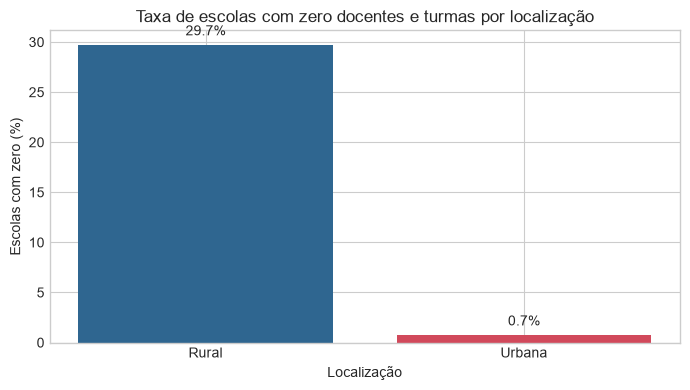

In [4]:
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(location_rates["localizacao"], location_rates["taxa_zeros"], color=["#2F6690", "#D1495B"])
ax.set_title("Taxa de escolas com zero docentes e turmas por localização")
ax.set_ylabel("Escolas com zero (%)")
ax.set_xlabel("Localização")
for i, value in enumerate(location_rates["taxa_zeros"]):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")
plt.tight_layout()
plt.show()


## 4. Distribuição de matrículas nos dois grupos

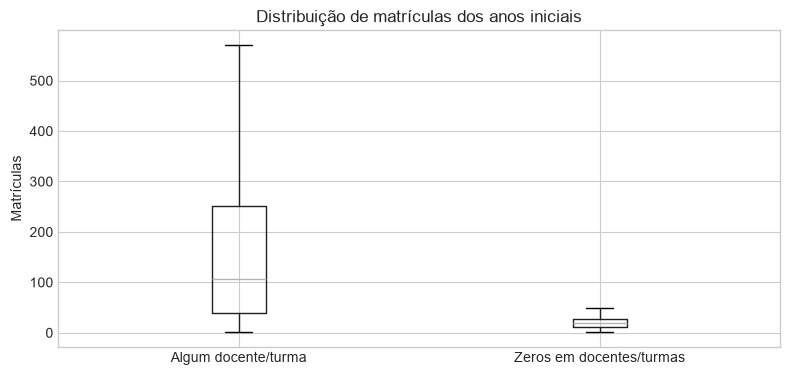

In [5]:
data["grupo"] = data["zero_doc_turma"].map({True: "Zeros em docentes/turmas", False: "Algum docente/turma"})
fig, ax = plt.subplots(figsize=(8, 4))
data.boxplot(column="QT_MAT_FUND_AI", by="grupo", ax=ax, showfliers=False)
ax.set_title("Distribuição de matrículas dos anos iniciais")
ax.set_xlabel("")
ax.set_ylabel("Matrículas")
fig.suptitle("")
plt.tight_layout()
plt.show()


## 5. Taxa por unidade federativa

In [6]:
by_uf = pd.read_csv(
    PROJECT_ROOT / "results" / "zeros_doc_turmas_por_uf.csv",
    encoding="utf-8-sig",
)
top_uf = by_uf.sort_values("percentual_zeros", ascending=False).head(10)
top_uf[["SG_UF", "escolas", "zeros_doc_turma", "percentual_zeros"]]


,SG_UF,escolas,zeros_doc_turma,percentual_zeros
0,AC,723,548,75.7953
1,PA,7379,2453,33.2430
2,MA,7195,2225,30.9243
3,ES,1364,359,26.3196
4,RN,1391,361,25.9526
5,AM,3930,900,22.9008
6,PI,2065,406,19.6610
7,PB,2212,426,19.2586
8,AP,305,55,18.0328
9,TO,665,114,17.1429


## 6. Decisão provisória

Os zeros são mantidos como observados. Eles não serão transformados automaticamente em nulos nem imputados. Como o padrão é fortemente rural e aparece em escolas com matrículas, docentes e turmas positivas no Ensino Fundamental geral, as variáveis específicas de docentes e turmas dos anos iniciais ficam fora da primeira modelagem até uma validação conceitual adicional.
